# Step 4a (option 2) — Fine-tune DocLayout-YOLO

Fine-tunes [DocLayout-YOLO](https://github.com/opendatalab/DocLayout-YOLO) on our
Labelbox-annotated pages, so it can detect Figure/Table regions on the other
~90 unannotated papers. This notebook calls straight into
`step04a_prepare_yolo_dataset.py` and `step04a_finetune_doclayout_yolo.py`
(same folder) rather than re-implementing their logic, so training progress,
plots, and metrics all render inline here as you run it.

**Folder layout this notebook expects:**
```
2026/
  My_code/
    step03_labelbox_export/step03_labelbox_export_to_dataset.py
    step04_detection/
      03_doclayout_yolo_finetune/   <- this notebook lives here
  Pre-Pages-2Annotate/               <- ndjson export + topic image folders
  Outputs/
```

## Before running the real thing

**Pretrained weights matter a lot here.** Our annotated set is small (10
papers, ~105 boxes across 4 classes) and spans many different journal
templates. Fine-tuning from a document-layout-pretrained checkpoint (not
training from scratch) is what makes that workable. Download the official
DocStructBench weights on a machine with normal internet access:

> https://huggingface.co/juliozhao/DocLayout-YOLO-DocStructBench

(grab the `.pt` file, e.g. `doclayout_yolo_docstructbench_imgsz1024.pt`) and
point `WEIGHTS` at its local path below. Leaving `WEIGHTS` as a bare
`.yaml` trains from a random initialization instead — only useful as a fast
smoke test of the pipeline, not for real detection accuracy.

**GPU strongly recommended.** The training cell uses 100 epochs, 1024-pixel
images, and batch size 8. Batch 32 exhausted MPS memory on the 48 GB M3 Max.
Device selection automatically uses CUDA, then Apple MPS (Mac GPU), then
CPU, depending on availability in PyTorch.


In [1]:
# Locate the project from either the project root or a notebook directory.
import os
import sys
from pathlib import Path
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                    if (p / "Pre-Pages-2Annotate").is_dir())
sys.path.insert(0, str(PROJECT_ROOT / "My_code"))
from annotation_inputs import latest_annotation_export, annotated_image_paths, build_image_index
os.chdir(PROJECT_ROOT / 'My_code/step04_detection/03_doclayout_yolo_finetune')
%matplotlib inline
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))
import step04a_prepare_yolo_dataset as prep
import step04a_finetune_doclayout_yolo as ft

# ── paths ──
ANNOTATIONS_ROOT = PROJECT_ROOT / "Pre-Pages-2Annotate" / "Exported_annotated_data"
NDJSON_PATH = latest_annotation_export(ANNOTATIONS_ROOT)
print(f"Annotation export: {NDJSON_PATH.name}")
IMAGES_ROOT = Path("../../../Pre-Pages-2Annotate")          # searched recursively across topic folders
YOLO_DATASET = Path("./yolo_dataset")                        # written by step 1 below

assert NDJSON_PATH.exists(), f"Export not found at {NDJSON_PATH.resolve()}"
assert IMAGES_ROOT.exists(), f"Images root not found at {IMAGES_ROOT.resolve()}"
print("Paths OK.")


Annotation export: Export  project - STEPS-Paper-Annotation - 9_23_2026.ndjson
Paths OK.


## Step 1 — Build the YOLO train/val split

Reuses step03's exact box-resolution logic (a `Figure_Mixed` composite's
outer box is kept, its nested Plot/Diagram sub-boxes are excluded -- see
step03's docstring for why). Splits by **paper**, not by page, so
validation actually measures generalization to a paper the model has never
seen, which is the real test for the other ~90 papers. Background
(no-graphics) pages are included as negative examples.


In [2]:
stats = prep.prepare_dataset(
    ndjson_path=NDJSON_PATH,
    images_root=IMAGES_ROOT,
    output_root=YOLO_DATASET,
    val_fraction=0.15,
)


──────────────────────────────────────────────────────
Papers total: 20  (val: 3)
Train: 228 pages, 181 boxes, 100 background
Val:   39 pages, 34 boxes, 13 background

Classes (4): ['Plot', 'Table', 'Diagram', 'Figure_Mixed']

Val papers (held out entirely, to test generalization to unseen papers):
    - Biomethane-production-enhancement-from-waste-activated-slud_2024_Journal-of-
    - Feasibility-of-alternative-sewage-sludge-treatment-meth_2020_Journal-of-Clea
    - Sustainable-reclamation-of-phosphorus-from-incinerated-sewa_2018_Journal-of-

Written to: /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/03_doclayout_yolo_finetune/yolo_dataset/
  data.yaml   <- pass this to the training script


## Step 2 — Fine-tune

`WEIGHTS` below points to the downloaded DocStructBench checkpoint beside
this notebook. The local training helper includes a compatibility fix for
DocLayout-YOLO 0.0.4: final checkpoint validation keeps the shared convolution
layers unfused. To make a short smoke test, temporarily set `EPOCHS = 1`.


In [3]:
DEVICE = ft.select_device()  # CUDA -> Apple MPS -> CPU
print(f"Training, validation, and prediction device: {DEVICE}")

WEIGHTS = "./doclayout_yolo_docstructbench_imgsz1024.pt"
assert Path(WEIGHTS).is_file(), f"Checkpoint not found: {WEIGHTS}"
EPOCHS  = 100                  # <-- bump way up (e.g. 50-150) for a real run
IMGSZ   = 1024                # <-- DocStructBench was trained at 1024; use that for the real run
BATCH   = 8                  # batch 32 exhausted MPS memory at 1024

model, metrics = ft.finetune(
    data=str(stats["data_yaml"]),
    weights=WEIGHTS,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    project="./runs",
    name="doclayout_finetune",
)


Training, validation, and prediction device: mps
Backend:  doclayout_yolo
Weights:  ./doclayout_yolo_docstructbench_imgsz1024.pt
Device:   mps
Ultralytics YOLOv0.0.4 🚀 Python-3.11.12 torch-2.9.1 MPS (Apple M3 Max)
engine/trainer: task=detect, mode=train, model=./doclayout_yolo_docstructbench_imgsz1024.pt, data=/Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/03_doclayout_yolo_finetune/yolo_dataset/data.yaml, epochs=100, time=None, patience=100, batch=8, imgsz=1024, save=True, save_period=10, val_period=1, cache=False, device=mps, workers=8, project=./runs, name=doclayout_finetune, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=Fa

train: Scanning /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/03_doclayout_yolo_finetune/yolo_dataset/labels/train... 228 images, 100 backgrounds, 0 corrupt: 100%|██████████| 228/228 [00:00<00:00, 5051.51it/s]

train: New cache created: /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/03_doclayout_yolo_finetune/yolo_dataset/labels/train.cache



val: Scanning /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/03_doclayout_yolo_finetune/yolo_dataset/labels/val... 39 images, 13 backgrounds, 0 corrupt: 100%|██████████| 39/39 [00:00<00:00, 4071.84it/s]

val: New cache created: /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/03_doclayout_yolo_finetune/yolo_dataset/labels/val.cache


Plotting labels to runs/doclayout_finetune/labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.00125, momentum=0.9) with parameter groups 171 weight(decay=0.0), 183 weight(decay=0.0005), 183 bias(decay=0.0)
Image sizes 1024 train, 1024 val
Using 0 dataloader workers
Logging results to runs/doclayout_finetune
Starting training for 100 epochs...
Apple GPU (MPS) tensor memory: 0.15 GiB. CUDA_mem does not apply on this Mac.

      Epoch    CUDA_mem     box_om     cls_om     dfl_om     box_oo     cls_oo     dfl_oo  Instances       Size


... (300 outputs left out)

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:09<00:00,  3.01s/it]


39
                   all         39         34      0.786      0.913       0.91      0.853
                  Plot         39         13      0.753      0.923      0.868      0.809
                 Table         39         11          1      0.787      0.905      0.813
               Diagram         39          6      0.601          1      0.972       0.93
          Figure_Mixed         39          4      0.788      0.941      0.895       0.86
Speed: 2.9ms preprocess, 146.3ms inference, 0.1ms postprocess per image
Results saved to runs/doclayout_finetune

Running validation on the held-out val split...
Ultralytics YOLOv0.0.4 🚀 Python-3.11.12 torch-2.9.1 MPS (Apple M3 Max)


val: Scanning /Users/md_halim_mondol/Desktop/STEPS-LLM/2026/My_code/step04_detection/03_doclayout_yolo_finetune/yolo_dataset/labels/val.cache... 39 images, 13 backgrounds, 0 corrupt: 100%|██████████| 39/39 [00:00<?, ?it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 5/5 [00:17<00:00,  3.46s/it]


39
                   all         39         34      0.786      0.913       0.91      0.853
                  Plot         39         13      0.753      0.923      0.868      0.809
                 Table         39         11          1      0.787      0.905      0.813
               Diagram         39          6      0.601          1      0.972       0.93
          Figure_Mixed         39          4      0.788      0.941      0.895       0.86
Speed: 5.7ms preprocess, 302.8ms inference, 9.2ms postprocess per image
Results saved to runs/doclayout_finetune

──────────────────────────────────────────────────────
mAP50:    0.9102
mAP50-95: 0.8532
  Plot               AP50=0.8684
  Table              AP50=0.9052
  Diagram            AP50=0.9721
  Figure_Mixed       AP50=0.8950

Best weights saved under: ./runs/doclayout_finetune/weights/best.pt


## Step 3 — Look at the results

Ultralytics writes several diagnostic plots per run (loss curves, PR curve,
confusion matrix, a grid of labeled training batches). Displaying them
inline here beats digging through the `runs/` folder by hand.


Run directory: runs/doclayout_finetune


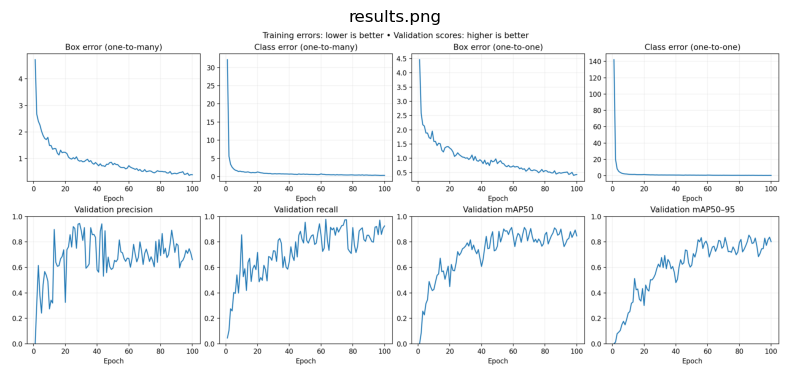

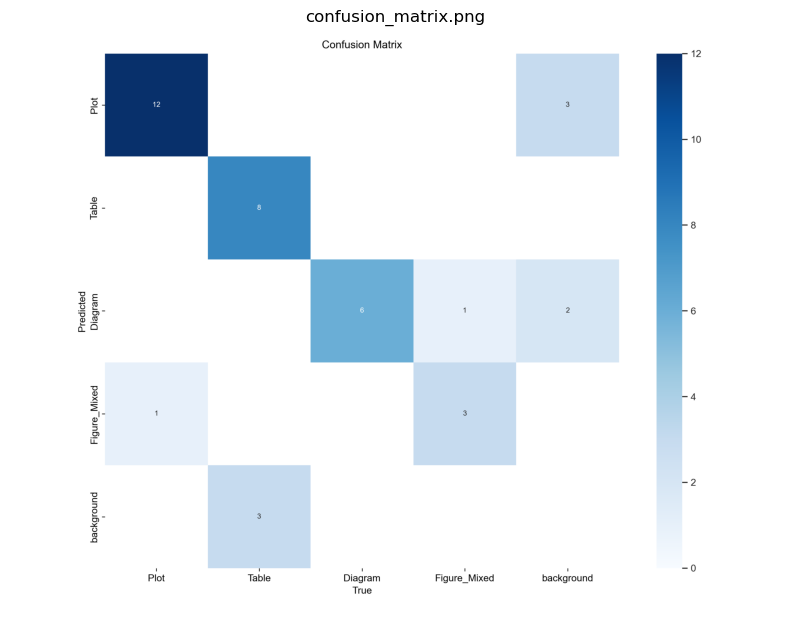

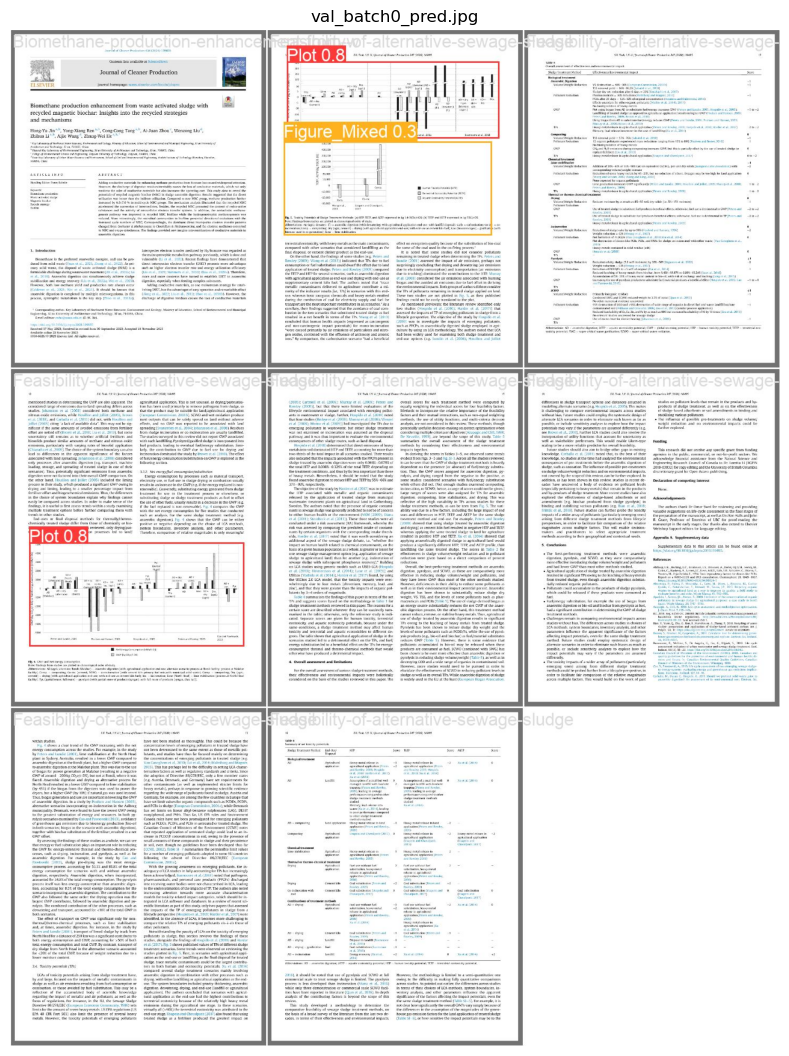

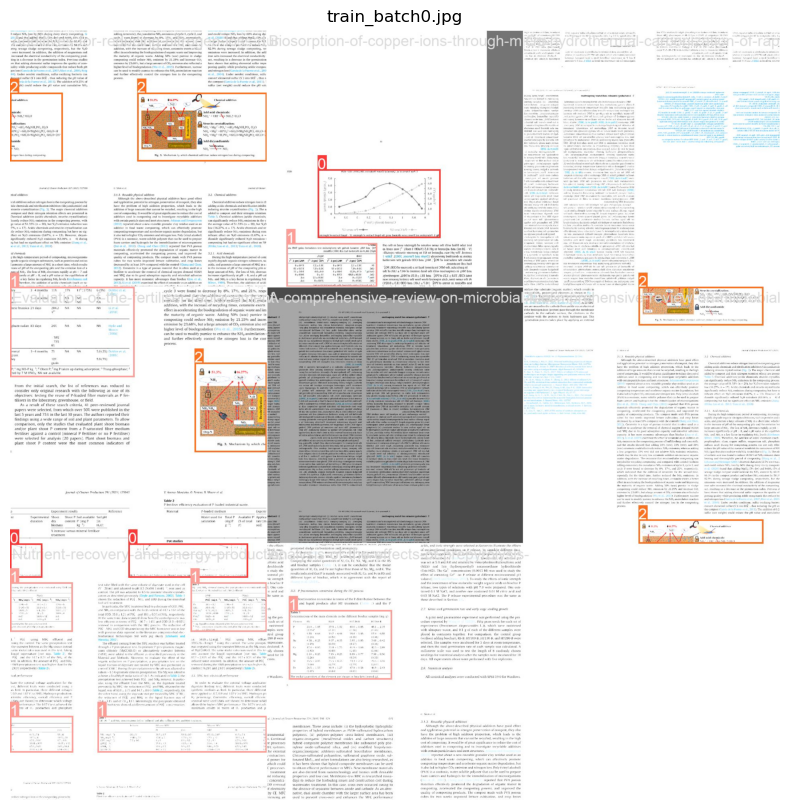

In [4]:
from PIL import Image
import matplotlib.pyplot as plt

run_dir = Path(model.trainer.save_dir)
print(f"Run directory: {run_dir}")

for fname in ["results.png", "confusion_matrix.png", "val_batch0_pred.jpg", "train_batch0.jpg"]:
    fpath = run_dir / fname
    if fpath.exists():
        img = Image.open(fpath)
        plt.figure(figsize=(10, 10 * img.size[1] / img.size[0]))
        plt.imshow(img)
        plt.axis("off")
        plt.title(fname)
        plt.show()
    else:
        print(f"(not found: {fname})")


## Step 4 — Preview several held-out pages with plots or figures

Select up to three validation pages whose ground-truth labels contain a
Plot, Diagram, or Figure_Mixed, then display the model predictions side by
side. Table-only and background pages are excluded. Change `PREVIEW_SEED`
to try another selection, or `N_PREVIEW` to show more pages.


Showing 3 of 18 validation pages with plots/figures.

0: 1024x768 1 Plot, 1 Figure_Mixed, 4604.4ms
1: 1024x768 1 Plot, 4604.4ms
2: 1024x768 1 Plot, 4604.4ms
Speed: 82.6ms preprocess, 4604.4ms inference, 163.6ms postprocess per image at shape (1, 3, 1024, 768)


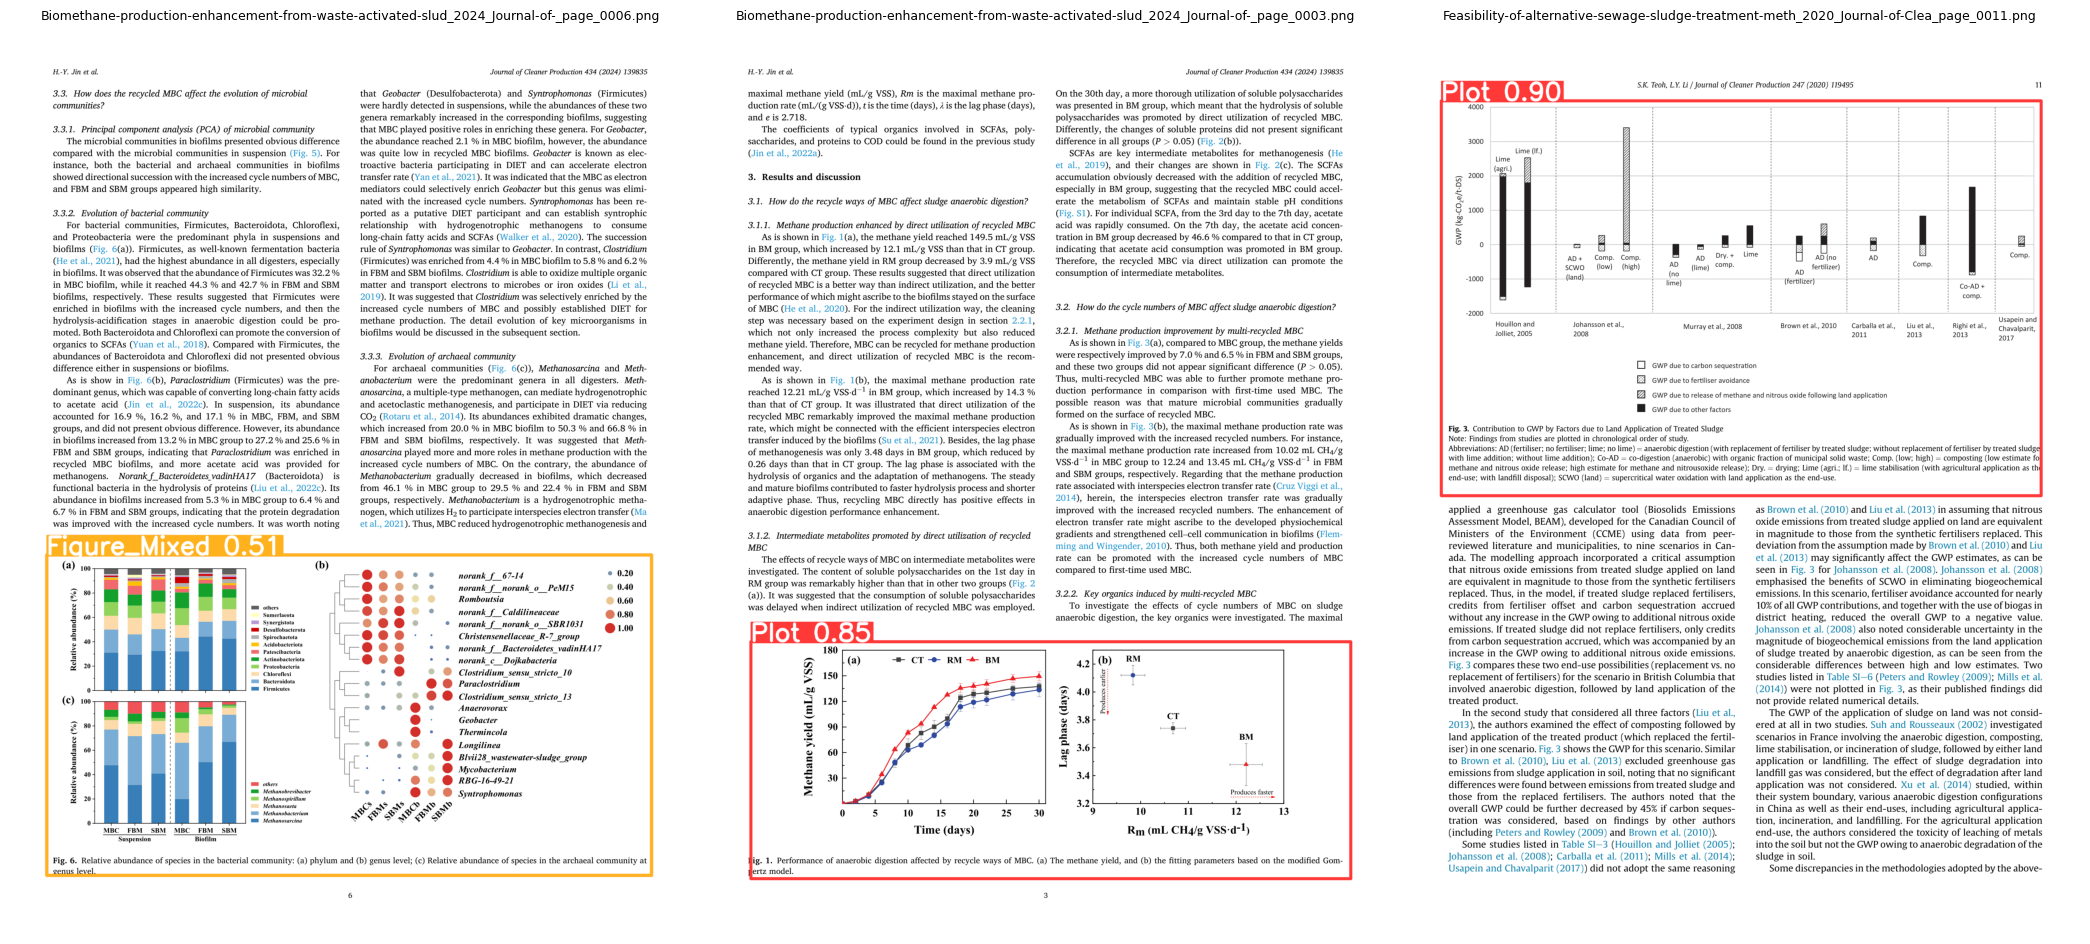

In [6]:
import random
import matplotlib.pyplot as plt

N_PREVIEW = 3
PREVIEW_SEED = 42

class_names = (YOLO_DATASET / "classes.txt").read_text().splitlines()
figure_ids = {i for i, name in enumerate(class_names)
              if name in {"Plot", "Diagram", "Figure_Mixed"}}
val_dir = YOLO_DATASET / "images" / "val"
label_dir = YOLO_DATASET / "labels" / "val"
candidates = []
for page in sorted(val_dir.iterdir()):
    if page.suffix.lower() not in {".png", ".jpg", ".jpeg"}:
        continue
    label_path = label_dir / f"{page.stem}.txt"
    if not label_path.is_file():
        continue
    present_ids = {int(line.split()[0]) for line in label_path.read_text().splitlines()
                   if line.strip()}
    if present_ids & figure_ids:
        candidates.append(page)

if candidates:
    sample_images = random.Random(PREVIEW_SEED).sample(
        candidates, min(N_PREVIEW, len(candidates)))
    print(f"Showing {len(sample_images)} of {len(candidates)} validation pages with plots/figures.")
    results = model.predict([str(page) for page in sample_images], device=DEVICE)
    fig, axes = plt.subplots(1, len(sample_images),
                             figsize=(7 * len(sample_images), 10), squeeze=False)
    for ax, page, result in zip(axes.flat, sample_images, results):
        annotated = result.plot()  # BGR numpy array with predicted boxes
        ax.imshow(annotated[..., ::-1])  # RGB for Matplotlib
        ax.set_title(page.name, fontsize=9, wrap=True)
        ax.axis("off")
    fig.tight_layout()
    plt.show()
else:
    print("No validation pages labeled Plot, Diagram, or Figure_Mixed were found.")
